In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import SGDClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score,
    f1_score
)

sns.set_theme(style="whitegrid")
os.makedirs("output", exist_ok=True)

# Load red wine dataset
df = pd.read_csv("winequality-red.csv", sep=";")

print("Dataset shape:", df.shape)
display(df.head())
print("\nColumn names:")
print(df.columns.tolist())

Dataset shape: (1599, 1)


,"fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality"
0,"7.4,0.7,0.0,1.9,0.076,11.0,34.0,0.9978,3.51,0...."
1,"7.8,0.88,0.0,2.6,0.098,25.0,67.0,0.9968,3.2,0...."
2,"7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.997,3.26,0..."
3,"11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.998,3.16,..."
4,"7.4,0.7,0.0,1.9,0.076,11.0,34.0,0.9978,3.51,0...."



Column names:
['fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality']


In [4]:
print(df.head())
print(df.columns.tolist())
print("Dataset shape:", df.shape)

  fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0  7.4,0.7,0.0,1.9,0.076,11.0,34.0,0.9978,3.51,0....                                                                                               
1  7.8,0.88,0.0,2.6,0.098,25.0,67.0,0.9968,3.2,0....                                                                                               
2  7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.997,3.26,0...                                                                                               
3  11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.998,3.16,...                                                                                               
4  7.4,0.7,0.0,1.9,0.076,11.0,34.0,0.9978,3.51,0....                                                                                               
['fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,d

In [12]:
print("Dataset columns:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

Dataset columns:
['fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality']

First 5 rows:


,"fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality"
0,"7.4,0.7,0.0,1.9,0.076,11.0,34.0,0.9978,3.51,0...."
1,"7.8,0.88,0.0,2.6,0.098,25.0,67.0,0.9968,3.2,0...."
2,"7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.997,3.26,0..."
3,"11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.998,3.16,..."
4,"7.4,0.7,0.0,1.9,0.076,11.0,34.0,0.9978,3.51,0...."


In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the CSV using comma as the separator
df = pd.read_csv("winequality-red.csv", sep=",")

# Clean column names
df.columns = df.columns.str.strip().str.lower()

# Verify the dataset
print("Column names:", df.columns.tolist())
print("Dataset shape:", df.shape)
display(df.head())

# Check the target column
print("\nWine quality counts:")
display(df["quality"].value_counts().sort_index())

Column names: ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'ph', 'sulphates', 'alcohol', 'quality']
Dataset shape: (1599, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,ph,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5



Wine quality counts:


quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64

In [16]:
print("Dataset information:")
df.info()

print("\nDescriptive statistics:")
display(df.describe().T)

print("\nMissing values per column:")
display(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nOriginal quality score counts:")
display(df["quality"].value_counts().sort_index())

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   ph                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB

Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
fixed acidity,1599.0,8.319637,1.741096,4.60000,7.1000,7.90000,9.200000,15.90000
volatile acidity,1599.0,0.527821,0.179060,0.12000,0.3900,0.52000,0.640000,1.58000
citric acid,1599.0,0.270976,0.194801,0.00000,0.0900,0.26000,0.420000,1.00000
residual sugar,1599.0,2.538806,1.409928,0.90000,1.9000,2.20000,2.600000,15.50000
chlorides,1599.0,0.087467,0.047065,0.01200,0.0700,0.07900,0.090000,0.61100
free sulfur dioxide,1599.0,15.874922,10.460157,1.00000,7.0000,14.00000,21.000000,72.00000
total sulfur dioxide,1599.0,46.467792,32.895324,6.00000,22.0000,38.00000,62.000000,289.00000
density,1599.0,0.996747,0.001887,0.99007,0.9956,0.99675,0.997835,1.00369
ph,1599.0,3.311113,0.154386,2.74000,3.2100,3.31000,3.400000,4.01000
sulphates,1599.0,0.658149,0.169507,0.33000,0.5500,0.62000,0.730000,2.00000



Missing values per column:


fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
ph                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64


Duplicate rows: 240

Original quality score counts:


quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64

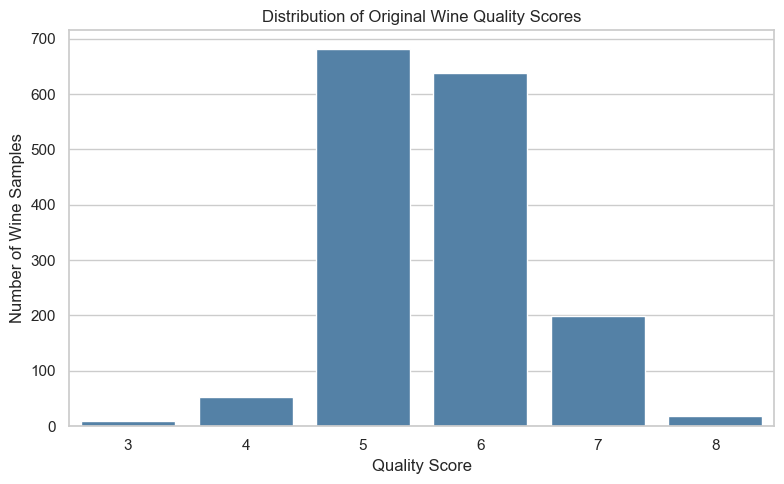

In [17]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="quality", color="steelblue")

plt.title("Distribution of Original Wine Quality Scores")
plt.xlabel("Quality Score")
plt.ylabel("Number of Wine Samples")
plt.tight_layout()
plt.show()

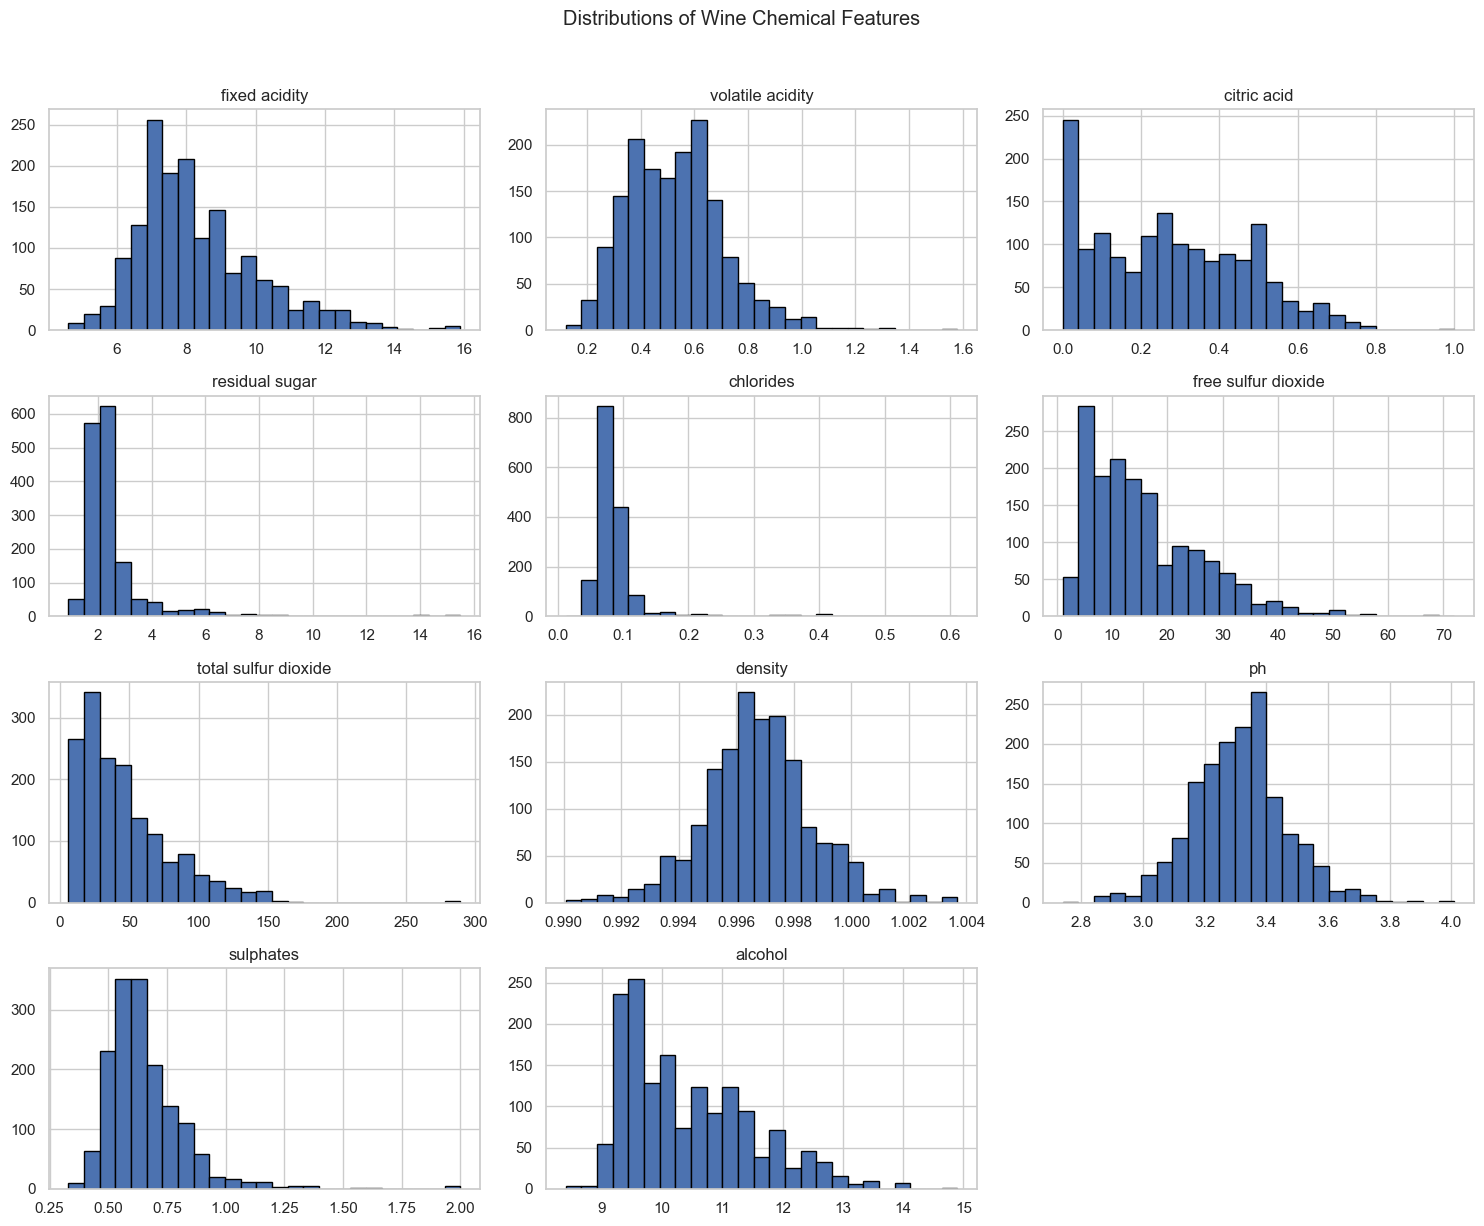

In [18]:
feature_columns = df.drop(columns="quality").columns

df[feature_columns].hist(
    figsize=(15, 12),
    bins=25,
    edgecolor="black"
)

plt.suptitle("Distributions of Wine Chemical Features", y=1.02)
plt.tight_layout()
plt.show()

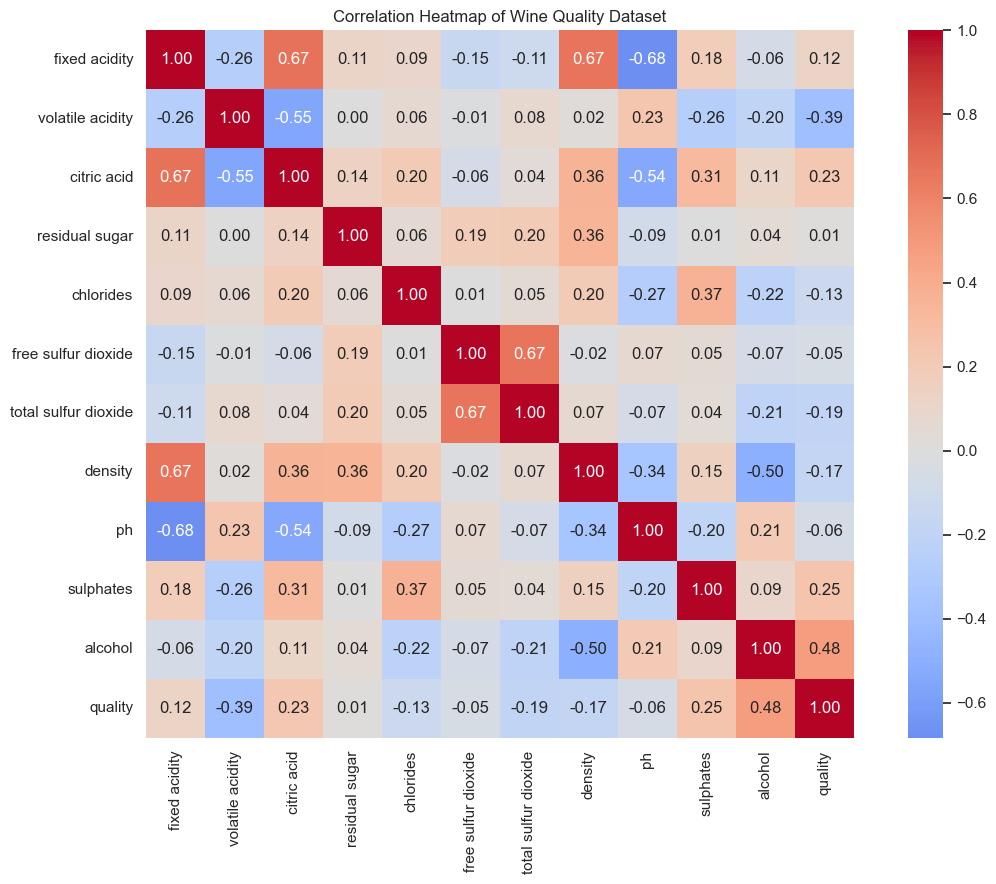

Correlation with original quality score:


alcohol                 0.476166
sulphates               0.251397
citric acid             0.226373
fixed acidity           0.124052
residual sugar          0.013732
free sulfur dioxide    -0.050656
ph                     -0.057731
chlorides              -0.128907
density                -0.174919
total sulfur dioxide   -0.185100
volatile acidity       -0.390558
Name: quality, dtype: float64

In [19]:
plt.figure(figsize=(12, 9))

correlation = df.corr(numeric_only=True)

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True
)

plt.title("Correlation Heatmap of Wine Quality Dataset")
plt.tight_layout()
plt.show()

print("Correlation with original quality score:")
display(
    correlation["quality"]
    .drop("quality")
    .sort_values(ascending=False)
)

Quality category counts:


quality_category
Medium    1319
High       217
Low         63
Name: count, dtype: int64


Class proportions:


quality_category
Medium    82.49
High      13.57
Low        3.94
Name: Percentage, dtype: float64

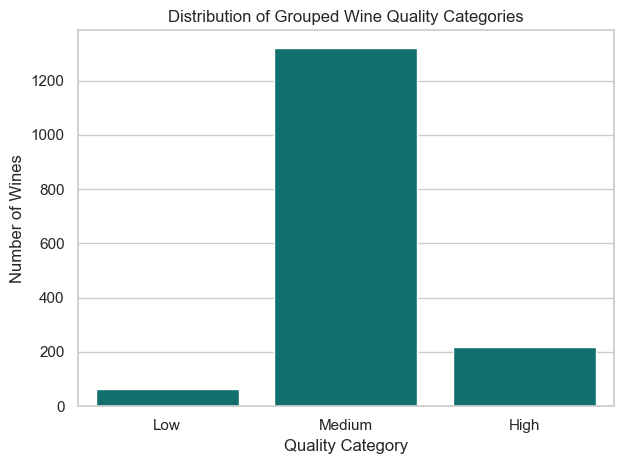

In [20]:
def quality_category(score):
    if score <= 4:
        return "Low"
    elif score <= 6:
        return "Medium"
    else:
        return "High"

df["quality_category"] = df["quality"].apply(quality_category)

print("Quality category counts:")
display(df["quality_category"].value_counts())

print("\nClass proportions:")
display(
    df["quality_category"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
    .rename("Percentage")
)

sns.countplot(
    data=df,
    x="quality_category",
    order=["Low", "Medium", "High"],
    color="teal"
)

plt.title("Distribution of Grouped Wine Quality Categories")
plt.xlabel("Quality Category")
plt.ylabel("Number of Wines")
plt.tight_layout()
plt.show()

In [21]:
# Inputs: chemical properties only
X = df.drop(columns=["quality", "quality_category"])

# Target: three-class quality category
y = df["quality_category"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

print("\nTraining class proportions:")
display(y_train.value_counts(normalize=True).round(3))

print("\nTesting class proportions:")
display(y_test.value_counts(normalize=True).round(3))

Training set: (1279, 11)
Testing set: (320, 11)

Training class proportions:


quality_category
Medium    0.825
High      0.136
Low       0.039
Name: proportion, dtype: float64


Testing class proportions:


quality_category
Medium    0.825
High      0.134
Low       0.041
Name: proportion, dtype: float64

In [22]:
models = {
    "Random Forest": Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", RandomForestClassifier(
            n_estimators=300,
            random_state=42,
            class_weight="balanced",
            n_jobs=-1
        ))
    ]),

    "SGD Classifier": Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", SGDClassifier(
            loss="hinge",
            max_iter=3000,
            tol=1e-3,
            random_state=42,
            class_weight="balanced"
        ))
    ]),

    "Support Vector Classifier": Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", SVC(
            kernel="rbf",
            C=1.0,
            gamma="scale",
            class_weight="balanced"
        ))
    ])
}

print("Three classifiers are ready.")

Three classifiers are ready.


In [23]:
results = []
trained_models = {}
predictions = {}

for name, model in models.items():
    print(f"\nTraining {name}...")

    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    trained_models[name] = model
    predictions[name] = y_pred

    accuracy = accuracy_score(y_test, y_pred)
    precision_macro = precision_score(
        y_test, y_pred, average="macro", zero_division=0
    )
    recall_macro = recall_score(
        y_test, y_pred, average="macro", zero_division=0
    )
    f1_macro = f1_score(
        y_test, y_pred, average="macro", zero_division=0
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Macro Precision": precision_macro,
        "Macro Recall": recall_macro,
        "Macro F1": f1_macro
    })

    print(f"\n{name} classification report:")
    print(classification_report(
        y_test,
        y_pred,
        labels=["Low", "Medium", "High"],
        zero_division=0
    ))

comparison_df = pd.DataFrame(results).sort_values(
    "Macro F1",
    ascending=False
)

print("\nModel comparison:")
display(comparison_df.round(4))


Training Random Forest...

Random Forest classification report:
              precision    recall  f1-score   support

         Low       0.00      0.00      0.00        13
      Medium       0.89      0.98      0.93       264
        High       0.80      0.56      0.66        43

    accuracy                           0.88       320
   macro avg       0.56      0.51      0.53       320
weighted avg       0.84      0.88      0.86       320


Training SGD Classifier...

SGD Classifier classification report:
              precision    recall  f1-score   support

         Low       0.09      0.15      0.11        13
      Medium       0.88      0.87      0.87       264
        High       0.49      0.42      0.45        43

    accuracy                           0.78       320
   macro avg       0.48      0.48      0.48       320
weighted avg       0.79      0.78      0.78       320


Training Support Vector Classifier...

Support Vector Classifier classification report:
              pre

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,Random Forest,0.8812,0.5632,0.5118,0.5296
2,Support Vector Classifier,0.7094,0.4712,0.5674,0.4892
1,SGD Classifier,0.7781,0.4849,0.4800,0.4789


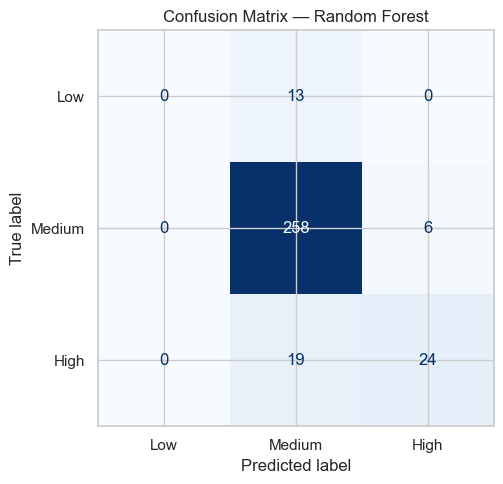

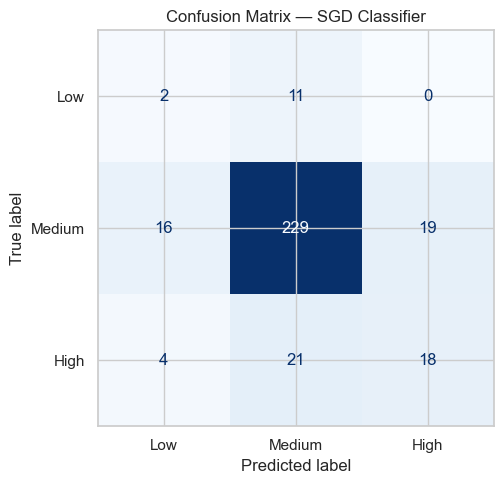

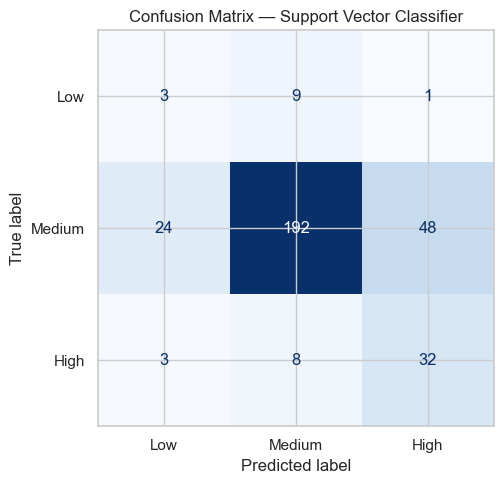

In [24]:
class_labels = ["Low", "Medium", "High"]

for name, y_pred in predictions.items():
    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=class_labels
    )

    display_cm = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_labels
    )

    fig, ax = plt.subplots(figsize=(6, 5))
    display_cm.plot(
        ax=ax,
        cmap="Blues",
        values_format="d",
        colorbar=False
    )

    ax.set_title(f"Confusion Matrix — {name}")
    plt.tight_layout()
    plt.savefig(
        f"output/confusion_matrix_{name.lower().replace(' ', '_')}.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()

,Feature,Importance
1,volatile acidity,0.152694
10,alcohol,0.145797
9,sulphates,0.133864
2,citric acid,0.102588
6,total sulfur dioxide,0.083132
8,ph,0.074544
4,chlorides,0.070007
5,free sulfur dioxide,0.061957
0,fixed acidity,0.061164
7,density,0.060341


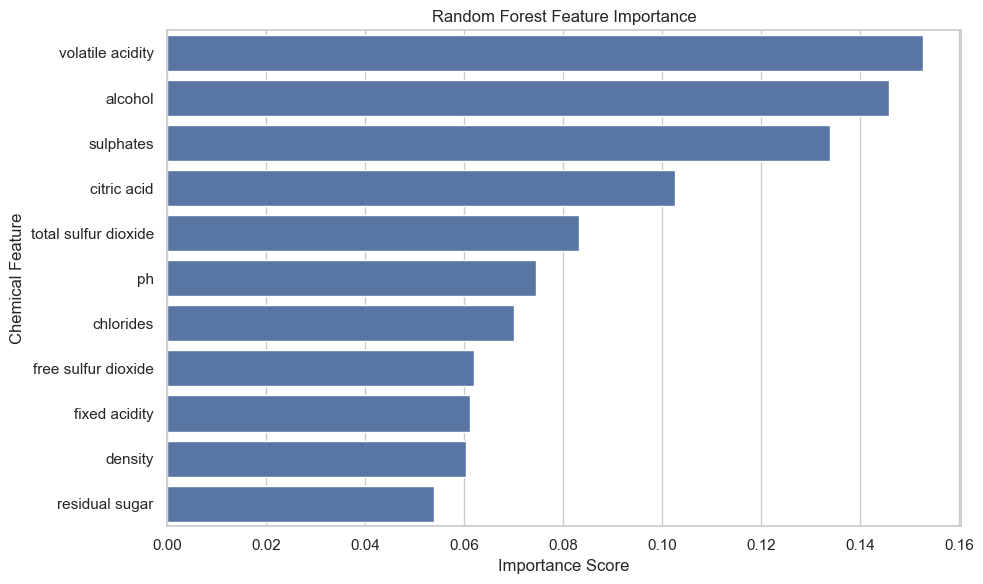

In [25]:
rf_model = trained_models["Random Forest"]
rf_classifier = rf_model.named_steps["classifier"]

importance_df = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_classifier.feature_importances_
}).sort_values("Importance", ascending=False)

display(importance_df)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Chemical Feature")
plt.tight_layout()
plt.savefig(
    "output/random_forest_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

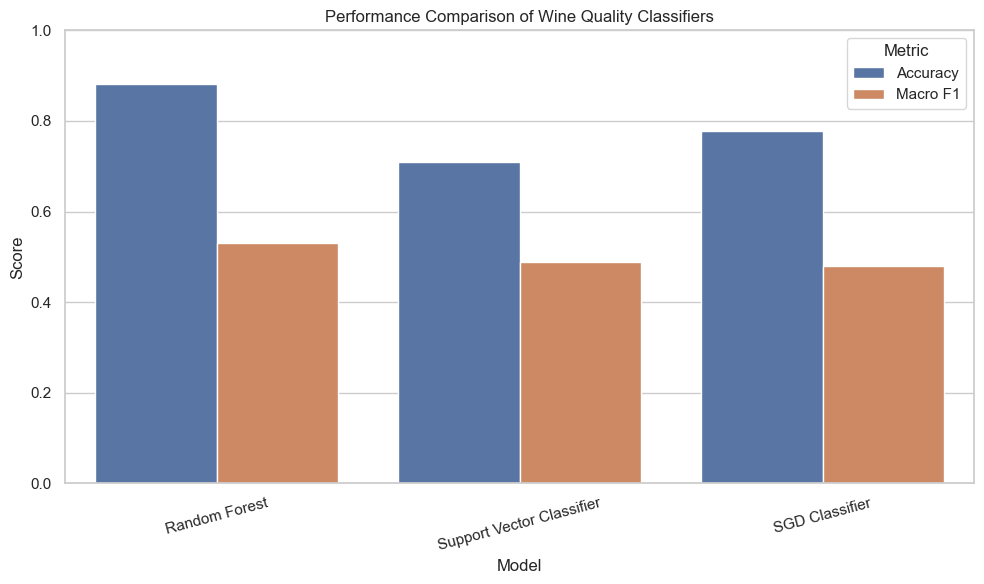

Saved model comparison and chart.


In [26]:
# Save comparison table
comparison_df.to_csv(
    "output/model_comparison.csv",
    index=False
)

# Compare accuracy and macro F1
metrics_to_plot = comparison_df.melt(
    id_vars="Model",
    value_vars=["Accuracy", "Macro F1"],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=metrics_to_plot,
    x="Model",
    y="Score",
    hue="Metric"
)

plt.title("Performance Comparison of Wine Quality Classifiers")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig(
    "output/model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Saved model comparison and chart.")

In [27]:
best_model_name = comparison_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

print("Best baseline model by macro F1:", best_model_name)
print(
    "Macro F1:",
    round(comparison_df.iloc[0]["Macro F1"], 4)
)
print(
    "Accuracy:",
    round(comparison_df.iloc[0]["Accuracy"], 4)
)

print("\nBest model classification report:")
print(classification_report(
    y_test,
    predictions[best_model_name],
    labels=["Low", "Medium", "High"],
    zero_division=0
))

Best baseline model by macro F1: Random Forest
Macro F1: 0.5296
Accuracy: 0.8812

Best model classification report:
              precision    recall  f1-score   support

         Low       0.00      0.00      0.00        13
      Medium       0.89      0.98      0.93       264
        High       0.80      0.56      0.66        43

    accuracy                           0.88       320
   macro avg       0.56      0.51      0.53       320
weighted avg       0.84      0.88      0.86       320



In [28]:
prediction_results = X_test.copy()
prediction_results["Actual_Category"] = y_test
prediction_results["Predicted_Category"] = predictions[best_model_name]

prediction_results.to_csv(
    "output/wine_quality_predictions.csv",
    index=False
)

importance_df.to_csv(
    "output/random_forest_feature_importance.csv",
    index=False
)

print("All results saved successfully.")

All results saved successfully.
